In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Flatten, Dropout
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.feature_selection import SelectKBest, chi2

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.22.0-rc0
GPU available: []


In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)
print("Classes:", np.unique(y_train))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


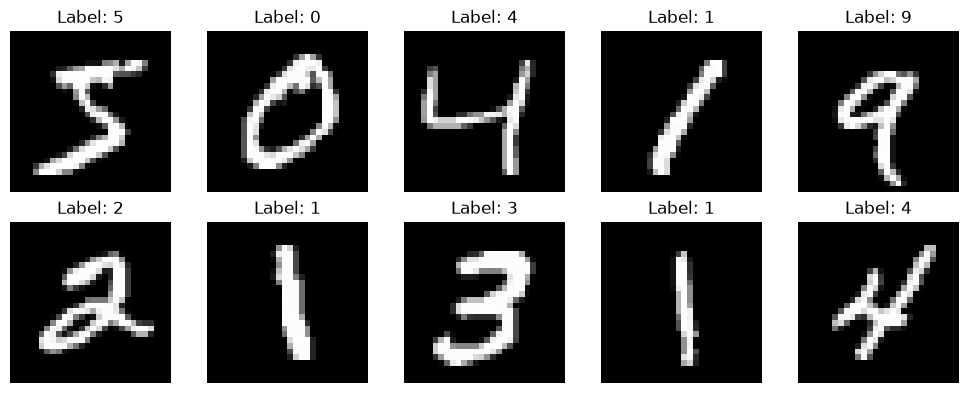

In [3]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

Preprocessing

In [4]:
# Normalize pixel values
X_train_normalized = X_train.astype("float32") / 255.0
X_test_normalized = X_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
X_train_flat = X_train_normalized.reshape(X_train_normalized.shape[0], 784)
X_test_flat = X_test_normalized.reshape(X_test_normalized.shape[0], 784)

# One-hot encode labels
y_train_encoded = to_categorical(y_train, 10)
y_test_encoded = to_categorical(y_test, 10)

print("After flattening:", X_train_flat.shape)
print("Encoded labels:", y_train_encoded.shape)
print("Pixel minimum:", X_train_normalized.min())
print("Pixel maximum:", X_train_normalized.max())

After flattening: (60000, 784)
Encoded labels: (60000, 10)
Pixel minimum: 0.0
Pixel maximum: 1.0


baseline ANN model

In [5]:
baseline_model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

training

In [6]:
history_baseline = baseline_model.fit(
    X_train_flat,
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9237 - loss: 0.2570 - val_accuracy: 0.9672 - val_loss: 0.1171
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9673 - loss: 0.1084 - val_accuracy: 0.9732 - val_loss: 0.0930
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9763 - loss: 0.0750 - val_accuracy: 0.9750 - val_loss: 0.0810
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9824 - loss: 0.0579 - val_accuracy: 0.9763 - val_loss: 0.0798
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9862 - loss: 0.0445 - val_accuracy: 0.9747 - val_loss: 0.0852
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9881 - loss: 0.0365 - val_accuracy: 0.9783 - val_loss: 0.0888
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9907 - loss: 0.0284 - val_accuracy: 0.9767 - val_loss: 0.0859
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9915 - loss: 0.0252 - 

Plot accuracy and loss

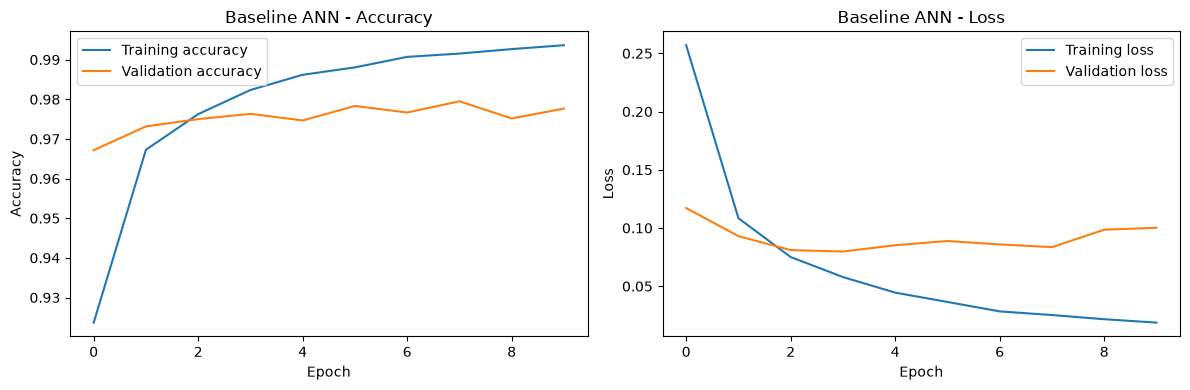

In [7]:
def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation accuracy")
    plt.title(title + " - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.title(title + " - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history_baseline, "Baseline ANN")

Evaluate the baseline model

In [8]:
baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test_flat, y_test_encoded, verbose=0
)

print("Baseline test loss:", round(baseline_loss, 4))
print("Baseline test accuracy:", round(baseline_accuracy, 4))

Baseline test loss: 0.1005
Baseline test accuracy: 0.9767


In [9]:
# Predict the class with the highest probability
y_pred_probability = baseline_model.predict(X_test_flat, verbose=0)
y_pred = np.argmax(y_pred_probability, axis=1)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.99      0.96      0.97      1032
           3       0.98      0.98      0.98      1010
           4       0.95      0.99      0.97       982
           5       0.97      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.97      0.98      0.97       974
           9       0.98      0.94      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



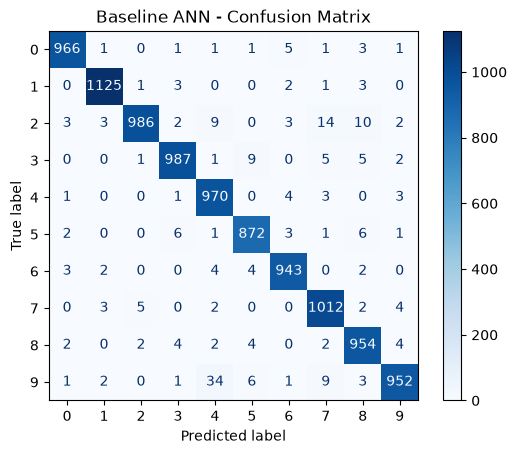

In [10]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm)
display.plot(cmap="Blues", values_format="d")
plt.title("Baseline ANN - Confusion Matrix")
plt.show()

Experiment 1 – Compare ANN architectures

compare a smaller network with the baseline network. The number of neurons and hidden layers can affect model capacity, training time, and performance.

To keep the experiment manageable, each model is trained for 5 epochs. Compare the test accuracy rather than assuming a larger network will always be better.

In [11]:
def build_ann(hidden_layers, activation="relu"):
    model = Sequential()
    model.add(Input(shape=(784,)))

    for units in hidden_layers:
        model.add(Dense(units, activation=activation))

    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

architecture_results = []

architectures = {
    "Small (64)": [64],
    "Baseline (128, 64)": [128, 64],
    "Larger (256, 128, 64)": [256, 128, 64]
}

for name, layers in architectures.items():
    model = build_ann(layers)

    model.fit(
        X_train_flat,
        y_train_encoded,
        epochs=5,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test_flat, y_test_encoded, verbose=0
    )

    architecture_results.append({
        "Architecture": name,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    })

architecture_results_df = pd.DataFrame(architecture_results)
architecture_results_df.sort_values(
    by="Test Accuracy", ascending=False
)

,Architecture,Test Loss,Test Accuracy
1,"Baseline (128, 64)",0.078765,0.9779
2,"Larger (256, 128, 64)",0.083418,0.9761
0,Small (64),0.091570,0.9720


Experiment 2 – Compare activation functions

In [12]:
activation_results = []
activation_models = {}

for activation in ["relu", "sigmoid", "tanh"]:
    model = build_ann([128, 64], activation=activation)

    model.fit(
        X_train_flat,
        y_train_encoded,
        epochs=5,
        batch_size=32,
        validation_split=0.1,
        verbose=0
    )

    test_loss, test_accuracy = model.evaluate(
        X_test_flat, y_test_encoded, verbose=0
    )

    activation_models[activation] = model
    activation_results.append({
        "Activation": activation,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy
    })

activation_results_df = pd.DataFrame(activation_results)
activation_results_df.sort_values(
    by="Test Accuracy", ascending=False
)

,Activation,Test Loss,Test Accuracy
0,relu,0.085776,0.9753
1,sigmoid,0.088293,0.9713
2,tanh,0.100426,0.9699


Experiment 3 – Feature selection

Each image has 784 input features (pixels). This experiment uses SelectKBest with the chi-squared score to keep the 300 most informative pixels.The chi-squared feature selector requires non-negative values.normalized pixel values are between 0 and 1, so they meet this requirement.

Feature selection is fitted only on the training data. The same selected columns are then applied to the test data to avoid data leakage.

In [13]:
selector = SelectKBest(score_func=chi2, k=300)

X_train_selected = selector.fit_transform(X_train_flat, y_train)
X_test_selected = selector.transform(X_test_flat)

print("Original number of features:", X_train_flat.shape[1])
print("Selected number of features:", X_train_selected.shape[1])

Original number of features: 784
Selected number of features: 300


Train and evaluate an ANN using selected features
The input layer now has 300 features instead of 784.

In [14]:
selected_model = Sequential([
    Input(shape=(300,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

selected_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

history_selected = selected_model.fit(
    X_train_selected,
    y_train_encoded,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

selected_loss, selected_accuracy = selected_model.evaluate(
    X_test_selected, y_test_encoded, verbose=0
)

print("Selected-feature test loss:", round(selected_loss, 4))
print("Selected-feature test accuracy:", round(selected_accuracy, 4))

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9102 - loss: 0.3001 - val_accuracy: 0.9573 - val_loss: 0.1470
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9597 - loss: 0.1296 - val_accuracy: 0.9682 - val_loss: 0.1122
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9706 - loss: 0.0937 - val_accuracy: 0.9703 - val_loss: 0.1002
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9769 - loss: 0.0725 - val_accuracy: 0.9753 - val_loss: 0.0904
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 992us/step - accuracy: 0.9807 - loss: 0.0603 - val_accuracy: 0.9735 - val_loss: 0.0964
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9844 - loss: 0.0488 - val_accuracy: 0.9770 - val_loss: 0.0855
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9861 - loss: 0.0409 - val_accuracy: 0.9730 - val_loss: 0.1061
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9879 - loss: 0.0352 

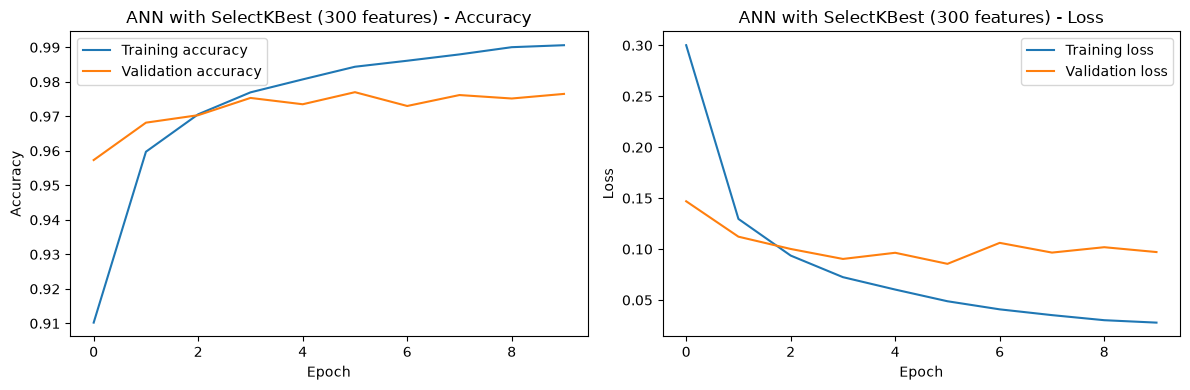

In [15]:
plot_history(history_selected, "ANN with SelectKBest (300 features)")

Compare the main results

In [16]:
comparison_df = pd.DataFrame([
    {
        "Model": "Baseline ANN (784 features)",
        "Number of Features": 784,
        "Test Accuracy": baseline_accuracy,
        "Test Loss": baseline_loss
    },
    {
        "Model": "ANN with SelectKBest",
        "Number of Features": 300,
        "Test Accuracy": selected_accuracy,
        "Test Loss": selected_loss
    }
])

comparison_df

,Model,Number of Features,Test Accuracy,Test Loss
0,Baseline ANN (784 features),784,0.9767,0.100521
1,ANN with SelectKBest,300,0.9732,0.095972


Test individual predictions

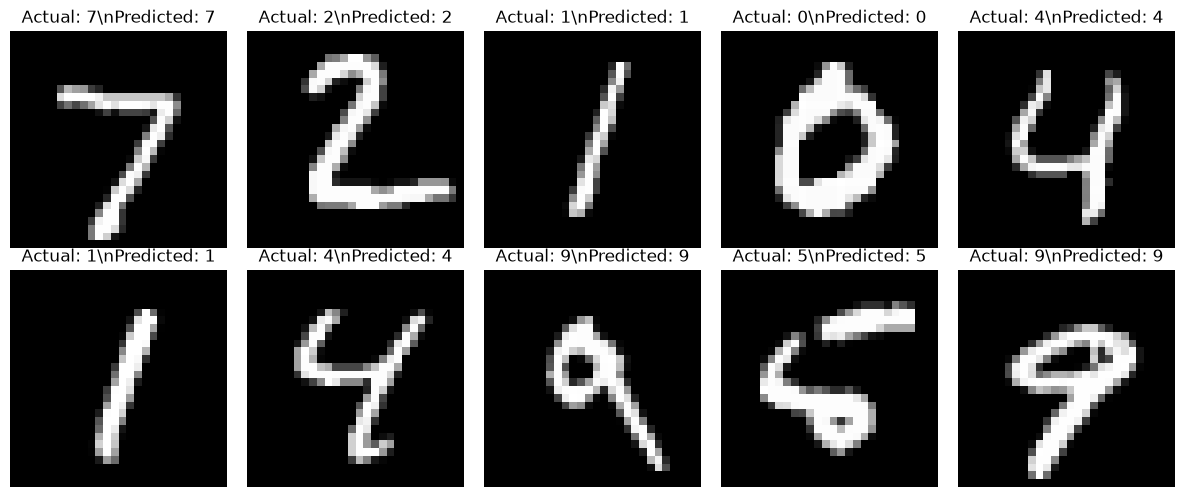

In [17]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title(
        "Actual: " + str(y_test[i]) +
        "\\nPredicted: " + str(y_pred[i])
    )
    plt.axis("off")

plt.tight_layout()
plt.show()